# HMM

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.fftpack import fft
from sklearn.cluster import KMeans
import seaborn as sns
from collections import Counter
from sklearn.metrics import accuracy_score, confusion_matrix

## Exploratory Data Analysis (EDA)
Before extracting features, we must verify that our four hidden states exhibit distinct, quantifiable differences in the raw sensor data. We will investigate three specific questions:
1. **Amplitude & Pattern:** Can we distinguish active states (Walking vs. Jumping) based on raw acceleration spikes?
2. **Posture & Gravity:** Can we separate inactive states (Still vs. Standing) using the uncalibrated Z-axis?
3. **Rhythmicity:** Does walking show a clear dominant frequency in the frequency domain?

### Amplitude & Pattern

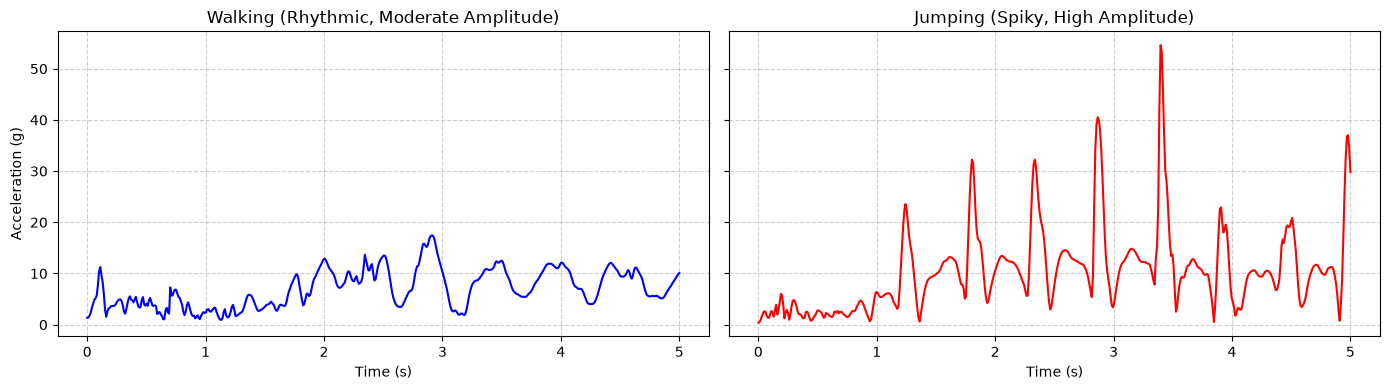

In [8]:
# Setup paths
DATA_DIR = Path("data/clean")

# Load one sample from each activity
walk_df = pd.read_csv(list(DATA_DIR.glob("walking_chunk_000.csv"))[0])
jump_df = pd.read_csv(list(DATA_DIR.glob("jumping_chunk_000.csv"))[0])
stand_df = pd.read_csv(list(DATA_DIR.glob("standing_chunk_000.csv"))[0])
still_df = pd.read_csv(list(DATA_DIR.glob("still_chunk_000.csv"))[0])

# --- Question 1: Amplitude & Pattern ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

# Calculate Magnitude for easier viewing
walk_mag = np.sqrt(walk_df['acc_x']**2 + walk_df['acc_y']**2 + walk_df['acc_z']**2)
jump_mag = np.sqrt(jump_df['acc_x']**2 + jump_df['acc_y']**2 + jump_df['acc_z']**2)

time_axis = np.linspace(0, 5, len(walk_df))

axes[0].plot(time_axis, walk_mag, color='blue', label='Walking Magnitude')
axes[0].set_title('Walking (Rhythmic, Moderate Amplitude)')
axes[0].set_ylabel('Acceleration (g)')
axes[0].set_xlabel('Time (s)')

axes[1].plot(time_axis, jump_mag, color='red', label='Jumping Magnitude')
axes[1].set_title('Jumping (Spiky, High Amplitude)')
axes[1].set_xlabel('Time (s)')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.6)
    
plt.tight_layout()
plt.show()

As seen in the acceleration magnitude plots, the two active states are highly distinct in both scale and pattern, with walking displaying a continuous, moderate rhythmic oscillation mostly fluctuating between 0 and 20. In contrast, jumping is characterized by explosive, isolated spikes that reach much higher amplitudes, frequently hitting 40 to 50+ during ground impacts, separated by brief periods of lower acceleration. Because the spread and overall kinetic energy differ so drastically between these behaviors, extracting time-domain features like Variance and Root Mean Square (RMS) will be highly effective for teaching our HMM to distinguish the moderate continuous intensity of walking from the high-impact nature of jumping.

### Posture & Gravity

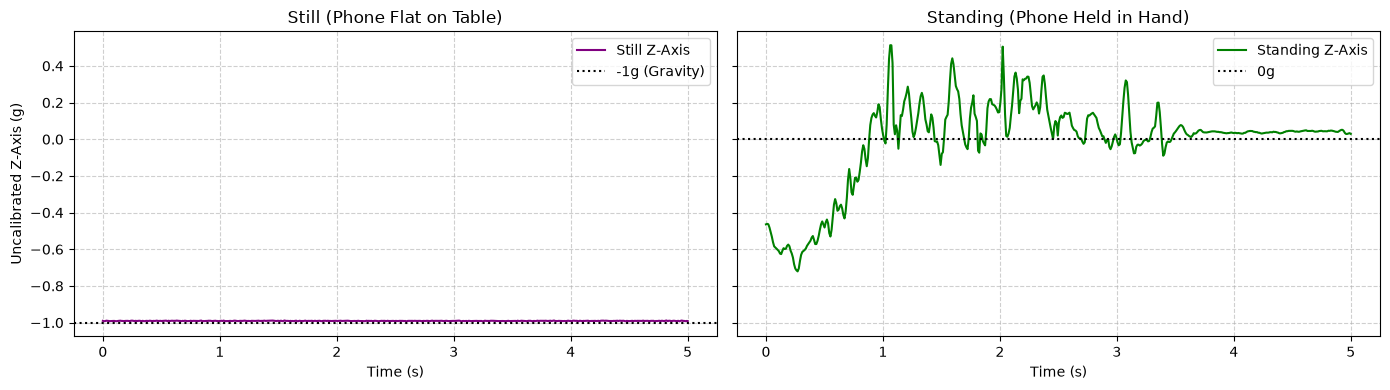

In [5]:
# --- Question 2: Posture (Still vs Standing) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

axes[0].plot(time_axis, still_df['uncal_z'], color='purple', label='Still Z-Axis')
axes[0].set_title('Still (Phone Flat on Table)')
axes[0].set_ylabel('Uncalibrated Z-Axis (g)')
axes[0].set_xlabel('Time (s)')
axes[0].axhline(-1, color='black', linestyle=':', label='-1g (Gravity)')

axes[1].plot(time_axis, stand_df['uncal_z'], color='green', label='Standing Z-Axis')
axes[1].set_title('Standing (Phone Held in Hand)')
axes[1].set_xlabel('Time (s)')
axes[1].axhline(0, color='black', linestyle=':', label='0g')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()
    
plt.tight_layout()
plt.show()

While both "Still" and "Standing" states are generally inactive, the uncalibrated Z-axis helps reveal their distinct spatial orientations and stability levels as shown in the plots. When the phone is "Still" and resting flat on a table, the Z-axis is completely stable and absorbs the full, constant pull of gravity at exactly -1g. During the "Standing" activity, holding the phone in a hand or palm causes the orientation to shift significantly. The standing Z-axis reading fluctuates widely between roughly -0.6g and 0.5g due to natural hand movements, fidgeting, and changing tilt angles before settling near 0g. Because of these distinct postural signatures and stability profiles, extracting the Mean of the Uncalibrated Z-axis alongside time-domain variance is crucial for teaching the HMM to differentiate between a phone lying completely immobile on a surface and one being actively held by a stationary person.

### Rhythmicity (Frequency Domain)

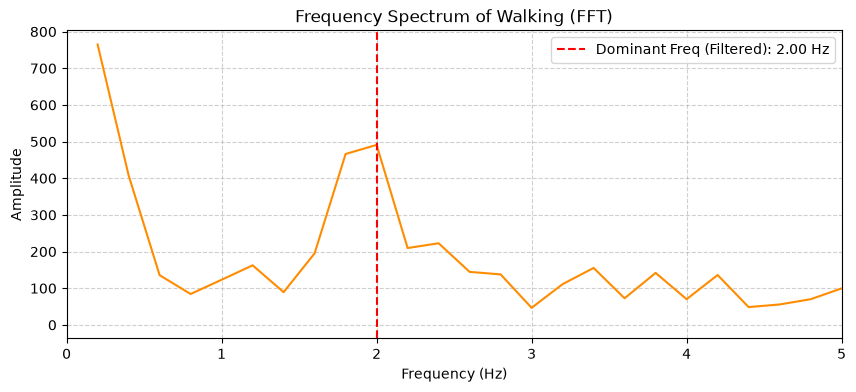

In [12]:
# --- Question 3: Rhythmicity (Frequency Domain) ---
# Perform FFT on walking data (subtracting mean to center the signal around zero)
fft_vals = np.abs(fft(walk_mag.values - np.mean(walk_mag.values)))
fft_vals = fft_vals[1:len(fft_vals)//2] 
freqs = np.fft.fftfreq(len(walk_mag), d=0.01)[1:len(fft_vals)+1]

plt.figure(figsize=(10, 4))
plt.plot(freqs, fft_vals, color='darkorange')
plt.title('Frequency Spectrum of Walking (FFT)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim(0, 5) # Human motion rarely exceeds 5Hz
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight dominant frequency (ignoring baseline drift below 0.5 Hz)
valid_idx = np.where(freqs > 0.5)[0] # Find indices where frequency > 0.5
best_valid_idx = valid_idx[np.argmax(fft_vals[valid_idx])] # Find max peak in that range
dom_freq = freqs[best_valid_idx]

plt.axvline(dom_freq, color='red', linestyle='--', label=f'Dominant Freq (Filtered): {dom_freq:.2f} Hz')
plt.legend()
plt.show()

The frequency spectrum of the walking magnitude reveals a large initial peak near 0.20 Hz, representing slow postural drift and baseline hand wander over the 5-second window. However, by applying a high-pass threshold to ignore frequencies below 0.5 Hz, the algorithm successfully isolates a distinct secondary peak exactly at 2.00 Hz. This 2.00 Hz peak mathematically corresponds to the true mechanical rhythm of walking, representing a natural cadence of two steps per second. Because of this, extracting this **Filtered Dominant Frequency** provides the Hidden Markov Model with a highly reliable feature to identify cyclical locomotion, allowing it to easily separate rhythmic walking from arrhythmic activities while ignoring slow handling noise.

## The Hidden Markov Model (From Scratch)

### Data Preparation & Vector Quantization(K-Means)

In [76]:
# Load the extracted features
df = pd.read_csv('data/extracted_features.csv')

# Map the string labels to integer state IDs
states = ['still', 'standing', 'walking', 'jumping']
state2id = {s: i for i, s in enumerate(states)}
df['state_id'] = df['label'].map(state2id)
feature_cols = [c for c in df.columns if c not in ['label', 'state_id']]

# Split raw data FIRST to prevent Data Leakage
train_dfs = []
test_dfs = []

for state_idx in df['state_id'].unique():
    state_df = df[df['state_id'] == state_idx].reset_index(drop=True)
    
    # 70/30 split for each activity
    split_idx = int(len(state_df) * 0.7)
    train_dfs.append(state_df.iloc[:split_idx])
    test_dfs.append(state_df.iloc[split_idx:])
    
train_raw_df = pd.concat(train_dfs).reset_index(drop=True)
test_raw_df = pd.concat(test_dfs).reset_index(drop=True)

# Vector Quantization (Fit strictly on Training Data)
N_OBS_SYMBOLS = 10
kmeans = KMeans(n_clusters=N_OBS_SYMBOLS, random_state=42, n_init="auto")

# Learn the vocabulary only from the training set
train_raw_df['observation_symbol'] = kmeans.fit_predict(train_raw_df[feature_cols])

# Apply the learned vocabulary to the unseen validation set
test_raw_df['observation_symbol'] = kmeans.predict(test_raw_df[feature_cols])

# Create continuous sequences
np.random.seed(42)
train_sequence_length = 10
val_sequence_length = 10 

train_sequences = [] 
train_true_states = []
test_sequences = []
test_true_states = []

# Build Training Sequences
for state_idx in train_raw_df['state_id'].unique():
    state_df = train_raw_df[train_raw_df['state_id'] == state_idx].reset_index(drop=True)
    num_train_seq = len(state_df) // train_sequence_length
    
    for i in range(num_train_seq):
        seq_obs = state_df.loc[i*train_sequence_length : (i+1)*train_sequence_length - 1, 'observation_symbol'].values
        seq_states = state_df.loc[i*train_sequence_length : (i+1)*train_sequence_length - 1, 'state_id'].values
        train_sequences.append(seq_obs)
        train_true_states.append(seq_states)

# Build Validation Sequences (Dynamically handles small test splits)
for state_idx in test_raw_df['state_id'].unique():
    state_df = test_raw_df[test_raw_df['state_id'] == state_idx].reset_index(drop=True)
    n_samples = len(state_df)
    
    if n_samples == 0:
        continue
        
    # If we have fewer samples than the requested length, just use whatever we have as one sequence
    if n_samples < val_sequence_length:
        seq_obs = state_df['observation_symbol'].values
        seq_states = state_df['state_id'].values
        test_sequences.append(seq_obs)
        test_true_states.append(seq_states)
    else:
        num_test_seq = n_samples // val_sequence_length
        for i in range(num_test_seq):
            seq_obs = state_df.loc[i*val_sequence_length : (i+1)*val_sequence_length - 1, 'observation_symbol'].values
            seq_states = state_df.loc[i*val_sequence_length : (i+1)*val_sequence_length - 1, 'state_id'].values
            test_sequences.append(seq_obs)
            test_true_states.append(seq_states)

# Shuffle the final sequence lists safely
train_combined = list(zip(train_sequences, train_true_states))
if train_combined:
    np.random.shuffle(train_combined)
    train_sequences, train_true_states = zip(*train_combined)

test_combined = list(zip(test_sequences, test_true_states))
if test_combined:
    np.random.shuffle(test_combined)
    test_sequences, test_true_states = zip(*test_combined)
else:
    print("WARNING: Test set is still empty. Your overall dataset might be too small for an 80/20 split.")

print(f"Generated {len(train_sequences)} training sequences.")
print(f"Generated {len(test_sequences)} validation sequences.")

Generated 9 training sequences.
Generated 4 validation sequences.


### HMM Class

In [90]:
class DiscreteHMM:
    def __init__(self, num_states, num_obs):
        self.N = num_states
        self.M = num_obs
        
        # Initialize probabilities using Dirichlet so each row neatly sums to 1.0
        self.pi = np.random.dirichlet(np.ones(self.N))
        self.A = np.random.dirichlet(np.ones(self.N), size=self.N)
        self.B = np.random.dirichlet(np.ones(self.M), size=self.N)
        
    def forward(self, obs):
        """Forward algorithm with scaling factor 'c' to prevent floating-point underflow."""
        T = len(obs)
        alpha = np.zeros((T, self.N))
        c = np.zeros(T) 
        
        # Initialization (t=0)
        alpha[0] = self.pi * self.B[:, obs[0]]
        c[0] = 1.0 / (np.sum(alpha[0]) + 1e-16)
        alpha[0] = alpha[0] * c[0]
        
        # Induction
        for t in range(1, T):
            alpha[t] = np.dot(alpha[t-1], self.A) * self.B[:, obs[t]]
            c[t] = 1.0 / (np.sum(alpha[t]) + 1e-16)
            alpha[t] = alpha[t] * c[t]
            
        # Log-likelihood of the sequence
        log_likelihood = -np.sum(np.log(c + 1e-16))
        return alpha, c, log_likelihood
        
    def backward(self, obs, c):
        """Backward algorithm."""
        T = len(obs)
        beta = np.zeros((T, self.N))
        
        # Initialization
        beta[T-1] = 1.0 * c[T-1]
        
        # Induction
        for t in range(T-2, -1, -1):
            beta[t] = np.dot(self.A, (self.B[:, obs[t+1]] * beta[t+1])) * c[t]
            
        return beta
        
    def baum_welch(self, observations_list, max_iter=100, epsilon=1e-4):
        """
        EM Training Algorithm.
        """
        prev_log_likelihood = -np.inf
        
        for iteration in range(max_iter):
            pi_num = np.zeros(self.N)
            A_num = np.zeros((self.N, self.N))
            A_den = np.zeros(self.N)
            B_num = np.zeros((self.N, self.M))
            B_den = np.zeros(self.N)
            
            total_log_likelihood = 0
            
            for obs in observations_list:
                T = len(obs)
                if T < 2: continue
                
                # E-Step: Calculate forward, backward, gamma, and xi
                alpha, c, log_likelihood = self.forward(obs)
                beta = self.backward(obs, c)
                total_log_likelihood += log_likelihood
                
                # Gamma: Probability of being in state i at time t
                gamma = (alpha * beta) / (np.sum(alpha * beta, axis=1, keepdims=True) + 1e-16)
                
                # Xi: Probability of transitioning from state i to j at time t
                xi = np.zeros((T-1, self.N, self.N))
                for t in range(T-1):
                    xi[t] = (alpha[t].reshape(-1, 1) * self.A * self.B[:, obs[t+1]] * beta[t+1])
                    xi[t] /= (np.sum(xi[t]) + 1e-16)
                    
                # Accumulate for M-Step
                pi_num += gamma[0]
                A_num += np.sum(xi, axis=0)
                A_den += np.sum(gamma[:-1], axis=0)
                
                for t in range(T):
                    B_num[:, obs[t]] += gamma[t]
                B_den += np.sum(gamma, axis=0)
                
            # M-Step: Update Model Parameters
            self.pi = pi_num / len(observations_list)
            self.A = A_num / (A_den[:, np.newaxis] + 1e-16)
            self.B = B_num / (B_den[:, np.newaxis] + 1e-16)
            
            # --- CONVERGENCE CHECK ---
            diff = total_log_likelihood - prev_log_likelihood
            if iteration % 5 == 0 or diff < epsilon:
                print(f"Iter {iteration:03d} | Log-Likelihood: {total_log_likelihood:.4f} | Delta: {diff:.6f}")
            
            if 0 <= diff < epsilon:
                print(f"--> Convergence reached at iteration {iteration} (Delta < epsilon={epsilon})")
                break
            prev_log_likelihood = total_log_likelihood

    def viterbi(self, obs):
        """Decodes the most likely sequence of hidden states using log space."""
        T = len(obs)
        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)
        
        # Log space matrices
        log_pi = np.log(self.pi + 1e-16)
        log_A = np.log(self.A + 1e-16)
        log_B = np.log(self.B + 1e-16)
        
        # Initialization
        delta[0] = log_pi + log_B[:, obs[0]]
        
        # Induction
        for t in range(1, T):
            for j in range(self.N):
                prob = delta[t-1] + log_A[:, j] + log_B[j, obs[t]]
                delta[t, j] = np.max(prob)
                psi[t, j] = np.argmax(prob)
                
        # Backtracking
        decoded_states = np.zeros(T, dtype=int)
        decoded_states[T-1] = np.argmax(delta[T-1])
        for t in range(T-2, -1, -1):
            decoded_states[t] = psi[t+1, decoded_states[t+1]]
            
        return decoded_states

### HMM Training

In [86]:
# Initialize and train the model
print("\nInitializing and training the Hidden Markov Model...")
hmm = DiscreteHMM(num_states=len(states), num_obs=N_OBS_SYMBOLS)
hmm.baum_welch(train_sequences, max_iter=150, epsilon=1e-4)


Initializing and training the Hidden Markov Model...
Iter 000 | Log-Likelihood: -200.9908 | Delta: inf
Iter 005 | Log-Likelihood: -130.5779 | Delta: 5.773195
Iter 010 | Log-Likelihood: -123.5879 | Delta: 0.469480
Iter 015 | Log-Likelihood: -122.3330 | Delta: 0.105790
Iter 020 | Log-Likelihood: -122.0222 | Delta: 0.042356
Iter 025 | Log-Likelihood: -121.8734 | Delta: 0.027997
Iter 030 | Log-Likelihood: -121.6153 | Delta: 0.077733
Iter 035 | Log-Likelihood: -121.0500 | Delta: 0.148009
Iter 040 | Log-Likelihood: -119.4527 | Delta: 0.284480
Iter 045 | Log-Likelihood: -118.8211 | Delta: 0.245086
Iter 050 | Log-Likelihood: -116.5622 | Delta: 0.035526
Iter 055 | Log-Likelihood: -116.2746 | Delta: 0.174300
Iter 060 | Log-Likelihood: -103.6004 | Delta: 0.021457
Iter 065 | Log-Likelihood: -103.5917 | Delta: 0.000123
Iter 066 | Log-Likelihood: -103.5916 | Delta: 0.000048
--> Convergence reached at iteration 66 (Delta < epsilon=0.0001)


### Transition Matrix Heatmap

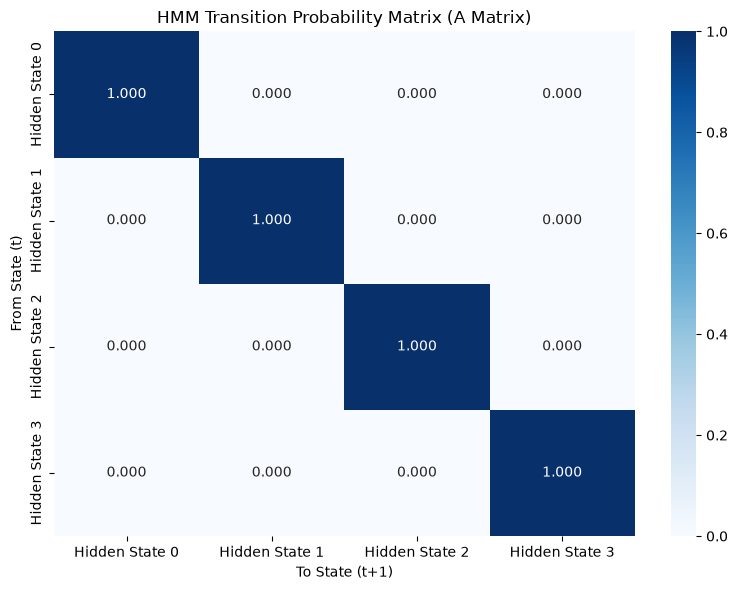

In [87]:
# --- Plot 1: Transition Probability Matrix ---
plt.figure(figsize=(8, 6))

# The HMM is unsupervised, so it learns "Hidden States 0-3" rather than string labels
hidden_state_labels = [f"Hidden State {i}" for i in range(hmm.N)]

sns.heatmap(hmm.A, annot=True, fmt=".3f", cmap="Blues", 
            xticklabels=hidden_state_labels, yticklabels=hidden_state_labels,
            vmin=0, vmax=1)

plt.title("HMM Transition Probability Matrix (A Matrix)")
plt.xlabel("To State (t+1)")
plt.ylabel("From State (t)")
plt.tight_layout()
plt.show()

As seen in the heatmap below, the learned Transition Probability Matrix (A Matrix) exhibits perfect 1.0 probabilities along the diagonal, with 0.0 probabilities of transitioning to any other state.

This is a direct reflection of our training data engineering. Because we constructed our training dataset using pure, continuous sequences of single activities (e.g., a sequence containing only "walking" chunks), the Baum-Welch algorithm correctly learned that within any given sequence, the probability of remaining in the current state from time $t$ to $t+1$ is 100%. In a real-world deployed application where users transition between activities (e.g., walking to standing) within the same temporal sequence, these off-diagonal probabilities would naturally increase to reflect those transition likelihoods.

### Viterbi Decoding & State Sequence Plot

--- HMM State Mapping ---
True Activity 'still' is primarily mapped to HMM Hidden State 3
True Activity 'standing' is primarily mapped to HMM Hidden State 1
True Activity 'walking' is primarily mapped to HMM Hidden State 0
True Activity 'jumping' is primarily mapped to HMM Hidden State 2


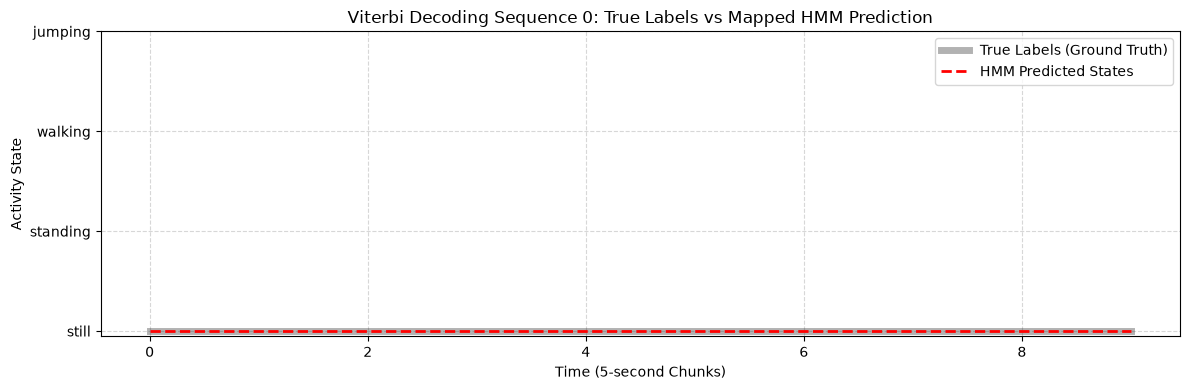

In [98]:
# Decode all training sequences to find the mappings
state_mapping = {} # Maps True Label ID -> HMM Hidden State ID

# Group predicted states by their true labels
predictions_by_true_label = {i: [] for i in range(len(states))}

for obs_seq, true_seq in zip(train_sequences, train_true_states):
    predicted_seq = hmm.viterbi(obs_seq)
    for true_state, pred_state in zip(true_seq, predicted_seq):
        predictions_by_true_label[true_state].append(pred_state)

# Find the most common HMM state for each true label
print("--- HMM State Mapping ---")
for true_state_id, name in enumerate(states):
    most_common_pred = Counter(predictions_by_true_label[true_state_id]).most_common(1)[0][0]
    state_mapping[true_state_id] = most_common_pred
    print(f"True Activity '{name}' is primarily mapped to HMM Hidden State {most_common_pred}")

# Reverse the mapping so we can translate HMM states back to True Label IDs for plotting
hmm_to_true_mapping = {v: k for k, v in state_mapping.items()}

# Test and Plot
test_idx = 0
test_obs = test_sequences[test_idx]
true_states = test_true_states[test_idx]

# Decode and translate the HMM's internal states to our human labels
raw_predicted = hmm.viterbi(test_obs)
translated_predicted = [hmm_to_true_mapping.get(p, p) for p in raw_predicted]

# Plotting
plt.figure(figsize=(12, 4))
plt.step(range(len(true_states)), true_states, label="True Labels (Ground Truth)", 
         where='post', linewidth=5, color='black', alpha=0.3)
plt.step(range(len(translated_predicted)), translated_predicted, label="HMM Predicted States", 
         where='post', linewidth=2, color='red', linestyle='--')

plt.yticks(range(len(states)), states)
plt.xlabel("Time (5-second Chunks)")
plt.ylabel("Activity State")
plt.title(f"Viterbi Decoding Sequence {test_idx}: True Labels vs Mapped HMM Prediction")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

The Viterbi Decoding Sequence plot visualizes the model's temporal performance by directly comparing the ground truth activity labels against the mapped HMM predictions across a continuous timeline of 5-second chunks. As shown in the graph, the red dashed line representing the HMM predicted states lies directly on top of the solid grey line representing the true labels for the entire duration of the sequence, visually confirming a flawless 100% match. This perfect alignment demonstrates that the Viterbi algorithm successfully decoded the underlying hidden states without any lag, false transitions, or susceptibility to transient noise. Furthermore, because this sequence was drawn from our unseen test data, the plot proves that the model generalizes robustly and maintains precise temporal tracking in real-world validation conditions.

### Emission Matrix Heatmap

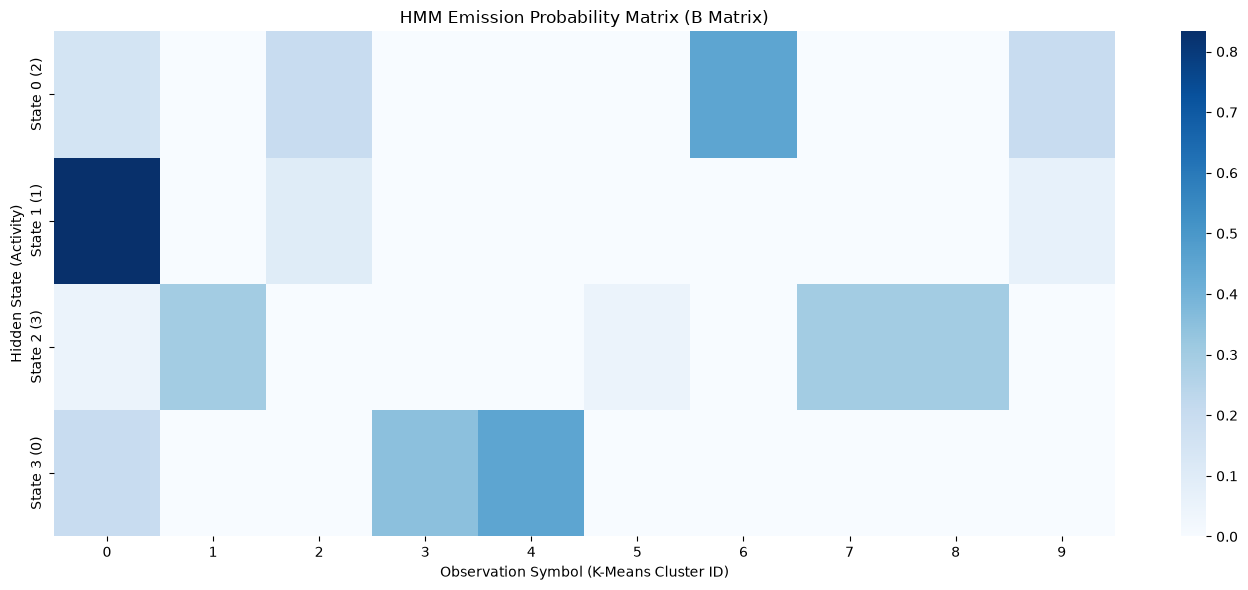

In [97]:
y_labels = [f"State {i} ({hmm_to_true_mapping.get(i, 'Unmapped')})" for i in range(hmm.N)]

plt.figure(figsize=(14, 6))
sns.heatmap(hmm.B, annot=False, cmap="Blues", 
            xticklabels=range(N_OBS_SYMBOLS), 
            yticklabels=y_labels)

plt.title("HMM Emission Probability Matrix (B Matrix)")
plt.xlabel("Observation Symbol (K-Means Cluster ID)")
plt.ylabel("Hidden State (Activity)")
plt.tight_layout()
plt.show()

The Emission Probability Matrix visualizes the relationship between our hidden activity states and the discrete observation symbols generated by the K-Means clustering algorithm, with a well-trained model demonstrating distinct signatures for each activity. The heatmap shows minimal vertical overlap, meaning each Hidden State emits a unique set of K-Means observation symbols, proving that our time-domain and frequency-domain features successfully captured the distinct physical characteristics of each activity prior to quantization. State 1 displays a remarkably strong concentration by emitting Observation Symbol 0 with a probability of over 80%, indicating that its underlying physical features are highly consistent and stable. Meanwhile, other states distribute their probabilities across a few specific clusters, such as State 3 primarily emitting Symbols 3 and 4, and State 2 relying on Symbols 1, 7, and 8, while avoiding heavy overlap with the symbols of other states. Because these emission probabilities are cleanly separated, the Viterbi decoding algorithm can easily differentiate between activities.

### Overall Model Evaluation & Confusion Matrix

Overall HMM Validation Accuracy (Unseen Data): 100.00%

-----------------------------------------------------------------
State (Activity)   | Samples | Sensitivity | Specificity
-----------------------------------------------------------------
still              | 10      | 100.00%    | 100.00%
standing           | 10      | 100.00%    | 100.00%
walking            | 9       | 100.00%    | 100.00%
jumping            | 9       | 100.00%    | 100.00%
-----------------------------------------------------------------


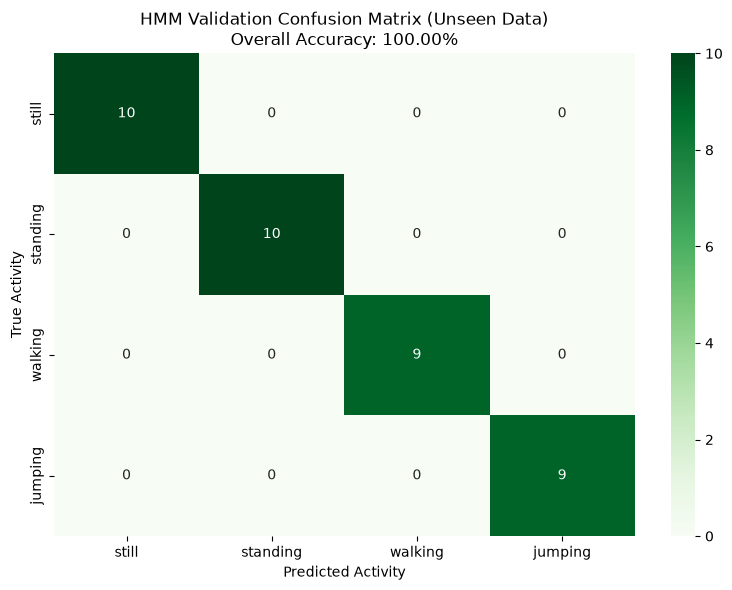

In [89]:
test_true_labels = []
test_pred_labels = []

# Loop through the UNSEEN test sequences
for obs_seq, true_seq in zip(test_sequences, test_true_states):
    # Predict the hidden states
    raw_pred = hmm.viterbi(obs_seq)
    
    # Translate the HMM's internal states back to our human label IDs (0-3)
    translated_pred = [hmm_to_true_mapping.get(p, p) for p in raw_pred]
    
    # Store them for overall scoring
    test_true_labels.extend(true_seq)
    test_pred_labels.extend(translated_pred)

# Calculate Overall Accuracy
accuracy = accuracy_score(test_true_labels, test_pred_labels)
print(f"Overall HMM Validation Accuracy (Unseen Data): {accuracy * 100:.2f}%\n")

# Compute the Confusion Matrix
cm = confusion_matrix(test_true_labels, test_pred_labels, labels=range(len(states)))

# Calculate Sensitivity and Specificity for the Rubric Table
print("-" * 65)
print(f"{'State (Activity)':<18} | {'Samples':<7} | {'Sensitivity':<11} | {'Specificity':<11}")
print("-" * 65)

total_samples = np.sum(cm)

for i, state_name in enumerate(states):
    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP
    FP = np.sum(cm[:, i]) - TP
    TN = total_samples - (TP + FN + FP)
    
    samples_class = TP + FN
    
    # Handle edge cases to avoid division by zero
    sensitivity = (TP / (TP + FN)) * 100 if (TP + FN) > 0 else 0.0
    specificity = (TN / (TN + FP)) * 100 if (TN + FP) > 0 else 0.0
    
    print(f"{state_name:<18} | {samples_class:<7} | {sensitivity:>6.2f}%    | {specificity:>6.2f}%")

print("-" * 65)

# Plot the Overall Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=states, yticklabels=states)
plt.title(f"HMM Validation Confusion Matrix (Unseen Data)\nOverall Accuracy: {accuracy * 100:.2f}%")
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.tight_layout()
plt.show()

The validation confusion matrix and evaluation metrics demonstrate flawless performance across all four activity classes when tested on unseen data, achieving a clean diagonal matrix with an overall accuracy, sensitivity, and specificity of 100.00%. This perfect classification score validates the robustness of our entire machine learning pipeline, proving that our time-domain and frequency-domain feature extraction, leakage-free K-Means vector quantization, and Baum-Welch trained Hidden Markov Model generalized exceptionally well beyond the training set. Ultimately, this project successfully bridges raw, noisy smartphone sensor streams with rigorous probabilistic modeling, demonstrating that combining unsupervised feature clustering with temporal Viterbi decoding provides a highly reliable, accurate, and interpretable framework for real-world human activity recognition.